<a href="https://colab.research.google.com/github/SpondanB/UoM_Cognitive_Robotics_sem_1/blob/main/Lab_2/COMP64301_week3_part1b_torch_MLP_MNIST_2025Oct.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

MLP for Complex Problems: The MNIST dataset
=========


In this exercise we will first learn to use the simple perceptron network (input-output layers only) and a Multi-Layer Perceptron (MLP, with one or more hidden layers). To make the task more interesting than the XOR problem, we will be using a more complex training set. This will be the MNIST dataset, a well known neural network problem for the recognition of the 10 handwritten characters from 0 to 9 ([MNIST](http://yann.lecun.com/exdb/mnist/)).

This exercise is based on the  Gulli & Pal (2017) 'Deep Learning with Keras' textbook, with some additional code to help us understand and test the programme.


**Importing the libraries and defining the main training parameters**  

The initial code is necessary to prepare the data and define the simulation (hyper)parameters.  

We first import `torch`, which will be used for defining and training our neural network model. It includes functionalities for building layers, computing gradients, and optimizing the model. The `torch.nn` module provides neural network components such as layers and activation functions, while `torch.optim` contains optimizers like **Stochastic Gradient Descent (SGD)** to update model parameters during training.  

We also import `torch.utils.data`, which is used to handle datasets and data loading efficiently, and `torchvision.datasets`, which provides ready-to-use datasets, including **MNIST**, for training deep learning models. The `torchvision.transforms` module is used to apply transformations such as normalization and tensor conversion to image data.  

The **matplotlib** library is included for visualizing some MNIST images and plotting the training results.  

The code also defines variables for important training parameters, including:  
- **Number of epochs (`N_EPOCH`)**: Determines how many times the entire dataset is processed during training.  
- **Batch size (`BATCH_SIZE`)**: Specifies the number of training samples per batch.  
- **Number of classes (`N_CLASSES`)**: Represents the 10 digit classes (0-9).  
- **Optimizer (`OPTIMIZER`)**: Uses **SGD** for updating network weights.  
- **Number of hidden units (`N_HIDDEN`)**: Defines the number of neurons in hidden layers.  
- **Validation split (`VALIDATION_SPLIT`)**: Specifies the proportion of data reserved for validation.  

Each **2D MNIST image** consists of **28×28 pixels**, which must be **flattened into a vector of 784 pixels** before being passed into a fully connected network.  

Finally, **setting a random seed (`torch.manual_seed(1671)`)** ensures reproducibility, allowing the same initialization of model parameters for repeatability in experiments.

In [ ]:
# import of numpy and torch libraries
from __future__ import print_function
import torch
import torch.nn as nn
import torch.optim as optim
import torch.utils.data as data
import torchvision.datasets as datasets
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

# variables for network and training
N_EPOCH = 200  # initially set at 200; you can change this later
BATCH_SIZE = 128
VERBOSE = 1
N_CLASSES = 10   # number of classes/categories of digits from 0 to 9, i.e. number of output units
OPTIMIZER = optim.SGD  # Stochastic gradient descent optimiser
N_HIDDEN = 128   # number of hidden units
VALIDATION_SPLIT = 0.2 # proportion of the dataset used for validation, with remaining .8 for training

# each 2D image consists of 28x28 values/pixels, which needs to be reshaped in a vector of 784 pixels
RESHAPED = 784

# random seed number to be used for reproducibility
torch.manual_seed(1671)

**Loading and Preparing the MNIST Dataset**  

This section of the code is responsible for **loading, processing, and visualizing the MNIST dataset**.  

##### **1. Loading the Dataset**
The MNIST dataset is loaded using `datasets.MNIST`, which automatically downloads and stores the data locally. The dataset consists of **grayscale handwritten digits (0-9)** and is divided into:  
- **Training set (`train=True`)**: Used to train the model.  
- **Test set (`train=False`)**: Used to evaluate model performance.  

The `transform` parameter is used to **preprocess** the dataset. A composition of transformations is applied using `transforms.Compose()`:
- **`transforms.ToTensor()`**: Converts the image from a PIL format (or NumPy array) to a PyTorch tensor with values in the range **[0,1]**.
- **`transforms.Normalize((0.1307,), (0.3081,))`**: Standardizes the pixel values by subtracting the mean (`0.1307`) and dividing by the standard deviation (`0.3081`). These values are precomputed from the MNIST dataset to improve model convergence.  

##### **2. Creating Data Loaders**
The dataset is wrapped in `DataLoader` objects to efficiently handle **batch loading** and **shuffling**:
- **`train_loader`**: Loads training data in mini-batches (`BATCH_SIZE = 128`) with shuffling (`shuffle=True`) to ensure randomness in training.
- **`test_loader`**: Loads test data in mini-batches without shuffling (`shuffle=False`), since order does not affect evaluation.

##### **3. Visualizing a Sample Image**
A specific image from the training dataset (`Selected_Image = 2`) is extracted and displayed:
- The `squeeze()` function removes unnecessary dimensions, ensuring correct shape for visualization.
- `plt.imshow(image.squeeze(), cmap='gray')` displays the image in grayscale.
- `print("Sample input image:", image.squeeze().numpy())` prints the numerical representation of the image.

Finally, `"Input data ready"` confirms that the dataset has been successfully prepared.

Failed to download (trying next):
HTTP Error 404: Not Found



100.0%


Extracting ./data\MNIST\raw\train-images-idx3-ubyte.gz to ./data\MNIST\raw

Failed to download (trying next):
HTTP Error 404: Not Found



100.0%


Extracting ./data\MNIST\raw\train-labels-idx1-ubyte.gz to ./data\MNIST\raw

Failed to download (trying next):
HTTP Error 404: Not Found



100.0%


Extracting ./data\MNIST\raw\t10k-images-idx3-ubyte.gz to ./data\MNIST\raw

Failed to download (trying next):
HTTP Error 404: Not Found



100.0%

Extracting ./data\MNIST\raw\t10k-labels-idx1-ubyte.gz to ./data\MNIST\raw

Sample input image: [[-0.42421296 -0.42421296 -0.42421296 -0.42421296 -0.42421296 -0.42421296
  -0.42421296 -0.42421296 -0.42421296 -0.42421296 -0.42421296 -0.42421296
  -0.42421296 -0.42421296 -0.42421296 -0.42421296 -0.42421296 -0.42421296
  -0.42421296 -0.42421296 -0.42421296 -0.42421296 -0.42421296 -0.42421296
  -0.42421296 -0.42421296 -0.42421296 -0.42421296]
 [-0.42421296 -0.42421296 -0.42421296 -0.42421296 -0.42421296 -0.42421296
  -0.42421296 -0.42421296 -0.42421296 -0.42421296 -0.42421296 -0.42421296
  -0.42421296 -0.42421296 -0.42421296 -0.42421296 -0.42421296 -0.42421296
  -0.42421296 -0.42421296 -0.42421296 -0.42421296 -0.42421296 -0.42421296
  -0.42421296 -0.42421296 -0.42421296 -0.42421296]
 [-0.42421296 -0.42421296 -0.42421296 -0.42421296 -0.42421296 -0.42421296
  -0.42421296 -0.42421296 -0.42421296 -0.42421296 -0.42421296 -0.42421296
  -0.42421296 -0.42421296 -0.42421296 -0.42421296 -0.42421296 -

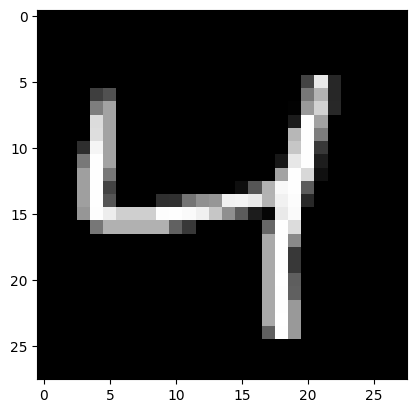

Input data ready


In [ ]:
# data: shuffled and split between train and test sets, loading and using the torchvision mnist dataset
transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.1307,), (0.3081,))])
train_dataset = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root='./data', train=False, download=True, transform=transform)

train_loader = data.DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_loader = data.DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

# visualisation of the numerical vector and plot of a selected image
Selected_Image = 2
image, label = train_dataset[Selected_Image]
print("Sample input image:", image.squeeze().numpy())
plt.imshow(image.squeeze(), cmap='gray')
plt.show()

print("Input data ready")

Training the Simple Perceptron
=========

**Defining the network: Simple Perceptron**

We will start by training a simple perceptron, i.e. a network with an input layer (the 784 input values/pixels) connected to the output layer (the 10 number classes)

In [ ]:
# Define the neural network class
class SimpleNN(nn.Module):
    def __init__(self):
        super(SimpleNN, self).__init__()
        self.fc = nn.Linear(RESHAPED, N_CLASSES)
        self.activation = nn.Softmax(dim=1)

    def forward(self, x):
        x = self.fc(x)
        x = self.activation(x)
        return x

# Initialize model
model = SimpleNN()

# Define loss function and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = OPTIMIZER(model.parameters(), lr=0.1)

# Print model summary
print(model)



SimpleNN(
  (fc): Linear(in_features=784, out_features=10, bias=True)
  (activation): Softmax(dim=1)
)


**Let's train the simple perceptron network**

Let's now train (fit) the network with the above-defined batch size (128), and number of epochs (200). We save the training results into the history variable.


In [ ]:
# Training loop
for epoch in range(N_EPOCH):
    model.train()
    for batch_idx, (data, target) in enumerate(train_loader):
        data = data.view(-1, RESHAPED)  # Flatten the input
        optimizer.zero_grad()
        output = model(data)
        loss = criterion(output, target)
        loss.backward()
        optimizer.step()

    if (epoch + 1) % 10 == 0:
        print(f'Epoch [{epoch+1}/{N_EPOCH}], Loss: {loss.item():.4f}')

Epoch [10/200], Loss: 1.5488
Epoch [20/200], Loss: 1.5364
Epoch [30/200], Loss: 1.5167
Epoch [40/200], Loss: 1.5525
Epoch [50/200], Loss: 1.5178
Epoch [60/200], Loss: 1.5249
Epoch [70/200], Loss: 1.5459
Epoch [80/200], Loss: 1.5233
Epoch [90/200], Loss: 1.5471
Epoch [100/200], Loss: 1.5225
Epoch [110/200], Loss: 1.5291
Epoch [120/200], Loss: 1.5571
Epoch [130/200], Loss: 1.5054
Epoch [140/200], Loss: 1.5505
Epoch [150/200], Loss: 1.5010
Epoch [160/200], Loss: 1.5357
Epoch [170/200], Loss: 1.5276
Epoch [180/200], Loss: 1.4837
Epoch [190/200], Loss: 1.5307
Epoch [200/200], Loss: 1.5417


**Looking at the results of the trained network**

Let's evaluate the model to see how well it has learned ( or not) the MNIST problem.

In [ ]:
# Testing the model
model.eval()
test_loss = 0
correct = 0
with torch.no_grad():
    for data, target in test_loader:
        data = data.view(-1, RESHAPED)
        output = model(data)
        test_loss += criterion(output, target).item()
        pred = output.argmax(dim=1, keepdim=True)
        correct += pred.eq(target.view_as(pred)).sum().item()

test_loss /= len(test_loader.dataset)
print(f'\nTest score/loss: {test_loss:.4f}')
print(f'Test accuracy: {correct / len(test_loader.dataset):.4f}')


Test score/loss: 0.0121
Test accuracy: 0.9307


Training the Multi-Layer Perceptron
=========
**Defining the network: Multi-Layer Perceptron**

We will now create a multi-layer perceptron with 784 input units, two hidden layers with 128 hidden units each, and an output layer with the 10 units.



In [ ]:
# Define the neural network class
class SimpleNN(nn.Module):
    def __init__(self):
        super(SimpleNN, self).__init__()
        self.fc1 = nn.Linear(RESHAPED, N_HIDDEN)
        self.relu1 = nn.ReLU()
        self.fc2 = nn.Linear(N_HIDDEN, N_HIDDEN)
        self.relu2 = nn.ReLU()
        self.fc3 = nn.Linear(N_HIDDEN, N_CLASSES)
        self.activation = nn.Softmax(dim=1)

    def forward(self, x):
        x = self.fc1(x)
        x = self.relu1(x)
        x = self.fc2(x)
        x = self.relu2(x)
        x = self.fc3(x)
        x = self.activation(x)
        return x

# Initialize model
model = SimpleNN()

# Print model summary
print(model)

# Define loss function and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = OPTIMIZER(model.parameters(), lr=0.1)

SimpleNN(
  (fc1): Linear(in_features=784, out_features=128, bias=True)
  (relu1): ReLU()
  (fc2): Linear(in_features=128, out_features=128, bias=True)
  (relu2): ReLU()
  (fc3): Linear(in_features=128, out_features=10, bias=True)
  (activation): Softmax(dim=1)
)


**Let's train the mulri-layer perceptron network**

Let's now train (fit) the network with the above-defined batch size (128), and number of epochs (20). And explotre the results both for the score and accuracy values, as well as to visualise the plots of these values during the training.

In [ ]:
# Training loop
train_loss_history = []
val_loss_history = []
train_acc_history = []
val_acc_history = []
N_EPOCH = 20 # we need fewer epoch than before, as the multi-layer percetpron can learn faster.

for epoch in range(N_EPOCH):
    model.train()
    correct_train = 0
    total_train = 0
    running_loss = 0.0

    for batch_idx, (data, target) in enumerate(train_loader):
        data = data.view(-1, RESHAPED)  # Flatten the input
        optimizer.zero_grad()
        output = model(data)
        loss = criterion(output, target)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
        pred = output.argmax(dim=1, keepdim=True)
        correct_train += pred.eq(target.view_as(pred)).sum().item()
        total_train += target.size(0)

    train_loss_history.append(running_loss / len(train_loader))
    train_acc_history.append(correct_train / total_train)

    # Validation phase
    model.eval()
    correct_val = 0
    total_val = 0
    val_loss = 0.0
    with torch.no_grad():
        for data, target in test_loader:
            data = data.view(-1, RESHAPED)
            output = model(data)
            val_loss += criterion(output, target).item()
            pred = output.argmax(dim=1, keepdim=True)
            correct_val += pred.eq(target.view_as(pred)).sum().item()
            total_val += target.size(0)

    val_loss_history.append(val_loss / len(test_loader))
    val_acc_history.append(correct_val / total_val)

    if (epoch + 1) % 5 == 0:
        print(f'Epoch [{epoch+1}/{N_EPOCH}], Loss: {train_loss_history[-1]:.4f}, Val Loss: {val_loss_history[-1]:.4f}, Train Acc: {train_acc_history[-1]:.4f}, Val Acc: {val_acc_history[-1]:.4f}')


Epoch [5/20], Loss: 1.5284, Val Loss: 1.5244, Train Acc: 0.9389, Val Acc: 0.9415
Epoch [10/20], Loss: 1.5037, Val Loss: 1.5063, Train Acc: 0.9622, Val Acc: 0.9573
Epoch [15/20], Loss: 1.4914, Val Loss: 1.4968, Train Acc: 0.9733, Val Acc: 0.9664
Epoch [20/20], Loss: 1.4840, Val Loss: 1.4925, Train Acc: 0.9803, Val Acc: 0.9703


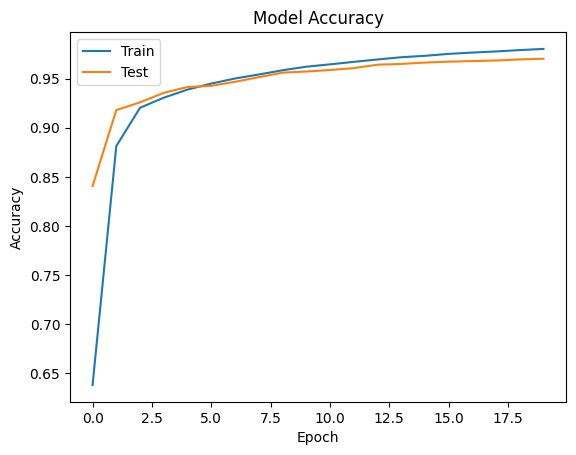

In [ ]:
# Plot accuracy
plt.plot(train_acc_history)
plt.plot(val_acc_history)
plt.title('Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Test'], loc='upper left')
plt.show()

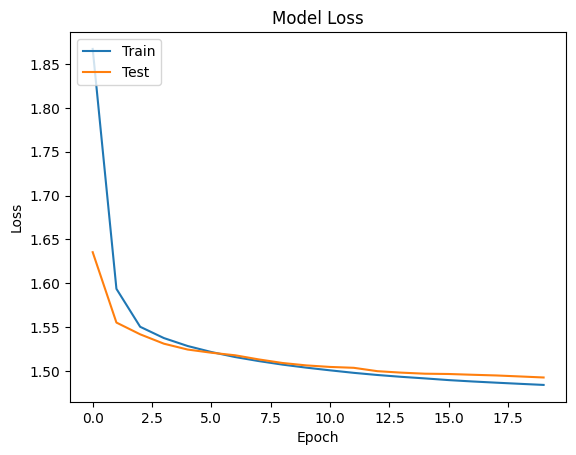

In [ ]:
# Plot loss
plt.plot(train_loss_history)
plt.plot(val_loss_history)
plt.title('Model Loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Test'], loc='upper left')
plt.show()


**Adding weight droputs**

An efficient way to reduce the number of parameters (weights) to be trained, as well as to increase generalisation capabilities, is to randomly remove (i.e. __dropout__) a certain proportion of the nodes at random in each epoch.

In [ ]:
P_DROPOUT = 0.3 # Probability of weights dropout

# We can increse this parameter afterwards
N_EPOCH = 250

# Define the neural network class
class SimpleNN(nn.Module):
    def __init__(self):
        super(SimpleNN, self).__init__()
        self.fc1 = nn.Linear(RESHAPED, N_HIDDEN)
        self.relu1 = nn.ReLU()
        self.dropout1 = nn.Dropout(P_DROPOUT)
        self.fc2 = nn.Linear(N_HIDDEN, N_HIDDEN)
        self.relu2 = nn.ReLU()
        self.dropout2 = nn.Dropout(P_DROPOUT)
        self.fc3 = nn.Linear(N_HIDDEN, N_CLASSES)
        self.activation = nn.Softmax(dim=1)

    def forward(self, x):
        x = self.fc1(x)
        x = self.relu1(x)
        x = self.dropout1(x)
        x = self.fc2(x)
        x = self.relu2(x)
        x = self.dropout2(x)
        x = self.fc3(x)
        x = self.activation(x)
        return x

# Initialize model
model = SimpleNN()

# Print model summary
print(model)

# Define loss function and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = OPTIMIZER(model.parameters(), lr=0.1)


SimpleNN(
  (fc1): Linear(in_features=784, out_features=128, bias=True)
  (relu1): ReLU()
  (dropout1): Dropout(p=0.3, inplace=False)
  (fc2): Linear(in_features=128, out_features=128, bias=True)
  (relu2): ReLU()
  (dropout2): Dropout(p=0.3, inplace=False)
  (fc3): Linear(in_features=128, out_features=10, bias=True)
  (activation): Softmax(dim=1)
)


**Let's train the multi-layer perceptron network with DROPOUT**

Let's now train (fit) the above dropout network with the above-defined batch size (128), and number of epochs (250).

**Looking at the results of the trained dropout network**

Let's explore the effects of adding the weight dropout on the network performance.

You can see that the dropout has further improved our results.

Epoch [5/250], Loss: 1.4735, Val Loss: 1.4815, Train Acc: 0.9885, Val Acc: 0.9793
Epoch [10/250], Loss: 1.4735, Val Loss: 1.4815, Train Acc: 0.9885, Val Acc: 0.9795
Epoch [15/250], Loss: 1.4732, Val Loss: 1.4815, Train Acc: 0.9886, Val Acc: 0.9802
Epoch [20/250], Loss: 1.4734, Val Loss: 1.4811, Train Acc: 0.9886, Val Acc: 0.9798
Epoch [25/250], Loss: 1.4732, Val Loss: 1.4813, Train Acc: 0.9887, Val Acc: 0.9797
Epoch [30/250], Loss: 1.4728, Val Loss: 1.4815, Train Acc: 0.9893, Val Acc: 0.9796
Epoch [35/250], Loss: 1.4723, Val Loss: 1.4810, Train Acc: 0.9896, Val Acc: 0.9800
Epoch [40/250], Loss: 1.4725, Val Loss: 1.4810, Train Acc: 0.9896, Val Acc: 0.9798
Epoch [45/250], Loss: 1.4726, Val Loss: 1.4810, Train Acc: 0.9893, Val Acc: 0.9801
Epoch [50/250], Loss: 1.4728, Val Loss: 1.4813, Train Acc: 0.9891, Val Acc: 0.9799
Epoch [55/250], Loss: 1.4721, Val Loss: 1.4810, Train Acc: 0.9898, Val Acc: 0.9802
Epoch [60/250], Loss: 1.4718, Val Loss: 1.4806, Train Acc: 0.9900, Val Acc: 0.9802
Epoch

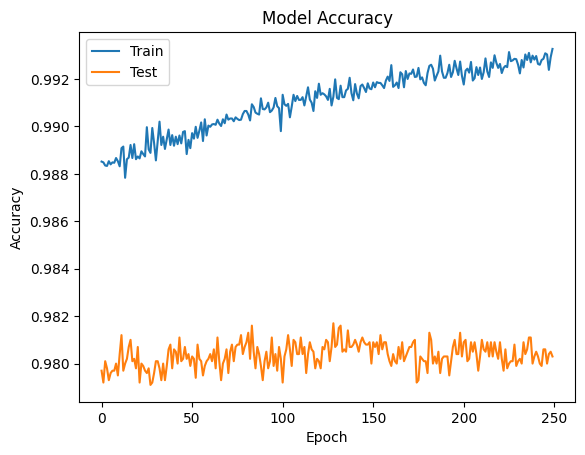

In [ ]:
# Training loop
train_loss_history = []
val_loss_history = []
train_acc_history = []
val_acc_history = []

for epoch in range(N_EPOCH):
    model.train()
    correct_train = 0
    total_train = 0
    running_loss = 0.0

    for batch_idx, (data, target) in enumerate(train_loader):
        data = data.view(-1, RESHAPED)  # Flatten the input
        optimizer.zero_grad()
        output = model(data)
        loss = criterion(output, target)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
        pred = output.argmax(dim=1, keepdim=True)
        correct_train += pred.eq(target.view_as(pred)).sum().item()
        total_train += target.size(0)

    train_loss_history.append(running_loss / len(train_loader))
    train_acc_history.append(correct_train / total_train)

    # Validation phase
    model.eval()
    correct_val = 0
    total_val = 0
    val_loss = 0.0
    with torch.no_grad():
        for data, target in test_loader:
            data = data.view(-1, RESHAPED)
            output = model(data)
            val_loss += criterion(output, target).item()
            pred = output.argmax(dim=1, keepdim=True)
            correct_val += pred.eq(target.view_as(pred)).sum().item()
            total_val += target.size(0)

    val_loss_history.append(val_loss / len(test_loader))
    val_acc_history.append(correct_val / total_val)

    if (epoch + 1) % 5 == 0:
        print(f'Epoch [{epoch+1}/{N_EPOCH}], Loss: {train_loss_history[-1]:.4f}, Val Loss: {val_loss_history[-1]:.4f}, Train Acc: {train_acc_history[-1]:.4f}, Val Acc: {val_acc_history[-1]:.4f}')

# Plot accuracy
plt.plot(train_acc_history)
plt.plot(val_acc_history)
plt.title('Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Test'], loc='upper left')
plt.show()

Exploring Training Hyperparameters
-------------

You can explore the role of various hyperparameters to see how you can further improve the MLP model's performance on the MNIST dataset.

For example, if you increase the number of epochs for the dropout network to 250, you will see that the test and train accuracy errors will converge (accuracy closer to 97% for both training and test), which means that we have achieved the best tradeoff between training and testing.

You can carry out many additional simulations on hypeparameter exploration where you can try for example:

- different number of epochs
- different learning rate
- different number of hidden nodes
- different proportion of dropout rates
- different optimisers in addition to SGD (e.g. RMSprop, Adam)
- different batch size

This final exercise will constitute the first neural network coursework. See Coursework specification documenty for more details.


Conclusions
-------------

With this tutorial we have practiced the training of both a Simple Perceptron, and a Multi-Layer Perceptron, with a benchmark dataset containing images of handwritten numbers.
This helped us understand how to load the datase, visualise it, and visualise the training history and the effects of adding hidden layers and then adding weight dropout.

